# DIMMN — Upgraded Pipeline
## Dyadic Interaction Multimodal Emotion Modeling (Improved)
**Thesis: Emotion-Conditioned Text-to-Speech via Multimodal Sequence Modeling**

Perubahan utama dari versi sebelumnya:
- ✅ Fitur audio diperkaya: MFCC + delta + delta-delta + Mel + pitch (F0) + energy (373-dim)
- ✅ Text embedding nyata: `all-MiniLM-L6-v2` sentence transformer (384-dim) menggantikan GloVe mock
- ✅ Speaker disimpan sebagai integer index untuk `nn.Embedding`, bukan one-hot
- ✅ Split data menggunakan protokol **Leave-One-Session-Out (LOSO)** — Session 5 sebagai test set
- ✅ Model: **BiLSTM + cross-modal attention + speaker embedding**
- ✅ Early stopping + model checkpointing berdasarkan weighted F1 (bukan loss)
- ✅ Ablation study τ (entropy gate)
- ✅ Baseline SVM untuk perbandingan novelty

## Cell 1 — Data Loading & Label Extraction
*Tidak ada perubahan dari versi sebelumnya — sudah benar.*

In [1]:
import os
import re
import pandas as pd
import pprint
from collections import defaultdict

# ── CONFIGURATION ──────────────────────────────────────────────────────────────
IEMOCAP_ROOT = r"D:\Kerja\data_thesis\IEMOCAP_full_release\IEMOCAP_full_release"

TARGET_EMOTIONS = {"hap", "sad", "ang", "neu"}
EMOTION_MAP     = {"hap": "happy", "sad": "sad", "ang": "angry", "neu": "neutral"}
EMOTION_TO_INT  = {"neutral": 0, "happy": 1, "sad": 2, "angry": 3}
INT_TO_EMOTION  = {v: k for k, v in EMOTION_TO_INT.items()}
SPEAKER_TO_IDX  = {"F": 0, "M": 1}

records = []

for session_num in range(1, 6):
    session_dir    = os.path.join(IEMOCAP_ROOT, f"Session{session_num}")
    eval_dir       = os.path.join(session_dir, "dialog", "EmoEvaluation")
    transcript_dir = os.path.join(session_dir, "dialog", "transcriptions")
    wav_dir        = os.path.join(session_dir, "sentences", "wav")

    for label_file in sorted(os.listdir(eval_dir)):
        if not label_file.endswith(".txt"):
            continue

        dialog_id      = label_file.replace(".txt", "")
        label_path     = os.path.join(eval_dir, label_file)
        transcript_path= os.path.join(transcript_dir, label_file)

        transcripts = {}
        if os.path.exists(transcript_path):
            with open(transcript_path, "r", encoding="latin-1", errors="ignore") as f:
                for line in f:
                    line = line.strip()
                    if ":" in line:
                        id_and_time, text = line.split(":", 1)
                        clean_utt_id = id_and_time.split()[0].strip()
                        transcripts[clean_utt_id] = text.strip()

        with open(label_path, "r", encoding="latin-1", errors="ignore") as f:
            for line in f:
                line = line.strip()
                if not line.startswith("["):
                    continue
                parts = line.split()
                if len(parts) < 5:
                    continue
                utt_id  = parts[3]
                emotion = parts[4]
                if emotion not in TARGET_EMOTIONS:
                    continue
                wav_path = os.path.join(wav_dir, dialog_id, f"{utt_id}.wav")
                records.append({
                    "session":      session_num,
                    "dialog_id":    dialog_id,
                    "utterance_id": utt_id,
                    "emotion":      EMOTION_MAP[emotion],
                    "label":        EMOTION_TO_INT[EMOTION_MAP[emotion]],
                    "text":         transcripts.get(utt_id, ""),
                    "wav_path":     wav_path,
                    "wav_exists":   os.path.exists(wav_path),
                })

df = pd.DataFrame(records)
print(f"Shape: {df.shape}")
print(df["emotion"].value_counts())
print(df.head())


Shape: (4490, 8)
emotion
neutral    1708
angry      1103
sad        1084
happy       595
Name: count, dtype: int64
   session       dialog_id         utterance_id  emotion  label  \
0        1  Ses01F_impro01  Ses01F_impro01_F000  neutral      0   
1        1  Ses01F_impro01  Ses01F_impro01_F001  neutral      0   
2        1  Ses01F_impro01  Ses01F_impro01_F002  neutral      0   
3        1  Ses01F_impro01  Ses01F_impro01_F005  neutral      0   
4        1  Ses01F_impro01  Ses01F_impro01_F012    angry      3   

                                          text  \
0                                   Excuse me.   
1                                        Yeah.   
2                          Is there a problem?   
3  Well what's the problem?  Let me change it.   
4                       That's out of control.   

                                            wav_path  wav_exists  
0  D:\Kerja\data_thesis\IEMOCAP_full_release\IEMO...        True  
1  D:\Kerja\data_thesis\IEMOCAP_full_release\IE

## Cell 2 — Build Conversation Sequences + EDA

In [2]:
def extract_turn_index(utterance_id):
    match = re.search(r'_[MF](\d+)$', utterance_id)
    return int(match.group(1)) if match else 0

def extract_speaker(utterance_id):
    return utterance_id.split('_')[-1][0]

df["turn_index"] = df["utterance_id"].apply(extract_turn_index)
df["speaker"]    = df["utterance_id"].apply(extract_speaker)
df = df.sort_values(["session", "dialog_id", "turn_index"]).reset_index(drop=True)

sequences = []
for dialog_id, group in df.groupby("dialog_id", sort=False):
    utts = group[["utterance_id", "emotion", "label", "text", "wav_path", "speaker"]].to_dict("records")
    sequences.append({
        "dialog_id":       dialog_id,
        "session":         group["session"].iloc[0],
        "utterances":      utts,
        "length":          len(utts),
        "emotion_sequence":[u["emotion"] for u in utts],
    })

print(f"Total dialogs: {len(sequences)}")
print(f"Rata-rata panjang sequence: {sum(s['length'] for s in sequences)/len(sequences):.1f}")
pprint.pprint(sequences[0])


Total dialogs: 151
Rata-rata panjang sequence: 29.7
{'dialog_id': 'Ses01F_impro01',
 'emotion_sequence': ['neutral',
                      'neutral',
                      'neutral',
                      'neutral',
                      'angry',
                      'angry',
                      'angry',
                      'neutral'],
 'length': 8,
 'session': np.int64(1),
 'utterances': [{'emotion': 'neutral',
                 'label': 0,
                 'speaker': 'F',
                 'text': 'Excuse me.',
                 'utterance_id': 'Ses01F_impro01_F000',
                 'wav_path': 'D:\\Kerja\\data_thesis\\IEMOCAP_full_release\\IEMOCAP_full_release\\Session1\\sentences\\wav\\Ses01F_impro01\\Ses01F_impro01_F000.wav'},
                {'emotion': 'neutral',
                 'label': 0,
                 'speaker': 'F',
                 'text': 'Yeah.',
                 'utterance_id': 'Ses01F_impro01_F001',
                 'wav_path': 'D:\\Kerja\\data_thesis\\IEMOCAP_fu

## Cell 3 — EDA: Transition Matrix, Word Count, Duration, Speaker Dynamics

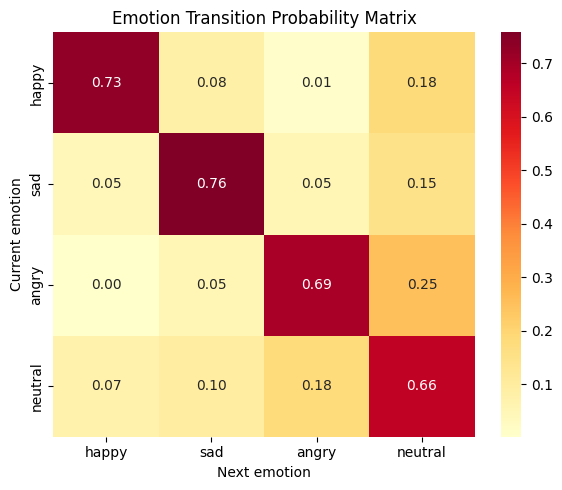

--- Text Length Stats ---
count    4490.000000
mean       11.203563
std        10.027140
min         1.000000
25%         4.000000
50%         8.000000
75%        15.000000
max        91.000000
Name: word_count, dtype: float64


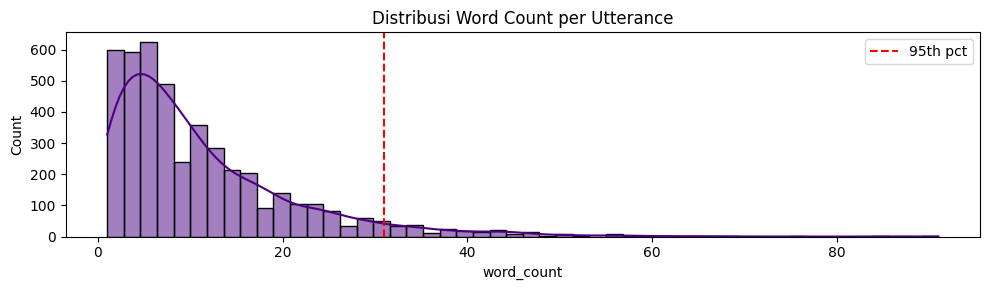


--- Audio Duration Stats ---
count    4490.000000
mean        4.495215
std         3.171135
min         0.730000
25%         2.321250
50%         3.509937
75%         5.699937
max        31.910000
Name: duration_sec, dtype: float64


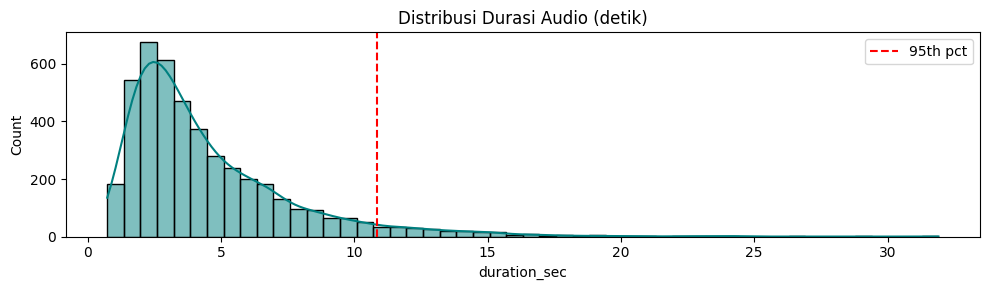


Total turn transitions : 4339
Speaker alternation    : 2472 (57.0%)


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import wave, contextlib

# ── Transition matrix ──────────────────────────────────────────────────────────
transition_counts = defaultdict(lambda: defaultdict(int))
for seq in sequences:
    emo = seq["emotion_sequence"]
    for i in range(len(emo) - 1):
        transition_counts[emo[i]][emo[i+1]] += 1

emo_labels = ["happy", "sad", "angry", "neutral"]
matrix = np.zeros((4, 4))
for i, fr in enumerate(emo_labels):
    total = sum(transition_counts[fr].values())
    for j, to in enumerate(emo_labels):
        matrix[i, j] = transition_counts[fr][to] / total if total > 0 else 0

plt.figure(figsize=(6, 5))
sns.heatmap(matrix, annot=True, fmt=".2f", xticklabels=emo_labels,
            yticklabels=emo_labels, cmap="YlOrRd")
plt.title("Emotion Transition Probability Matrix")
plt.ylabel("Current emotion"); plt.xlabel("Next emotion")
plt.tight_layout(); plt.show()

# ── Word count distribution ────────────────────────────────────────────────────
df["word_count"] = df["text"].apply(lambda x: len(str(x).split()))
print("--- Text Length Stats ---")
print(df["word_count"].describe())

plt.figure(figsize=(10, 3))
sns.histplot(df["word_count"], bins=50, kde=True, color="indigo")
plt.axvline(df["word_count"].quantile(0.95), color="red", linestyle="--", label="95th pct")
plt.title("Distribusi Word Count per Utterance"); plt.legend(); plt.tight_layout(); plt.show()

# ── Audio duration ─────────────────────────────────────────────────────────────
def get_audio_duration(wav_path):
    try:
        with contextlib.closing(wave.open(wav_path, "r")) as f:
            return f.getnframes() / float(f.getframerate())
    except:
        return 0.0

df["duration_sec"] = df["wav_path"].apply(get_audio_duration)
print("\n--- Audio Duration Stats ---")
print(df["duration_sec"].describe())

plt.figure(figsize=(10, 3))
sns.histplot(df["duration_sec"], bins=50, kde=True, color="teal")
plt.axvline(df["duration_sec"].quantile(0.95), color="red", linestyle="--", label="95th pct")
plt.title("Distribusi Durasi Audio (detik)"); plt.legend(); plt.tight_layout(); plt.show()

# ── Speaker dynamics ───────────────────────────────────────────────────────────
total_trans, speaker_changes = 0, 0
for seq in sequences:
    speakers = [extract_speaker(u["utterance_id"]) for u in seq["utterances"]]
    for i in range(len(speakers)-1):
        total_trans += 1
        if speakers[i] != speakers[i+1]:
            speaker_changes += 1

print(f"\nTotal turn transitions : {total_trans}")
print(f"Speaker alternation    : {speaker_changes} ({100*speaker_changes/total_trans:.1f}%)")


## Cell 4 — SVM Baseline (WAJIB untuk klaim novelty)
Kita harus punya angka pembanding. Baseline ini **tidak** menggunakan informasi sequence — 
hanya fitur per-utterance. Jika model DIMMN kita mengalahkan ini, klaim novelty kita valid.

In [4]:
import librosa
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report

# Ekstraksi fitur MFCC sederhana untuk SVM (utterance-level, tanpa sequence)
def extract_mfcc_simple(wav_path, sr=16000, max_sec=10, n_mfcc=40):
    try:
        y, _ = librosa.load(wav_path, sr=sr, duration=max_sec)
        if len(y) < sr * max_sec:
            y = np.pad(y, (0, sr * max_sec - len(y)))
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
        return np.concatenate([np.mean(mfcc, axis=1), np.std(mfcc, axis=1)])
    except:
        return np.zeros(n_mfcc * 2)

print("Mengekstrak fitur MFCC untuk SVM baseline...")
print("(Ini memproses per utterance, bukan per sequence)")

# LOSO split: Session 1-4 = train, Session 5 = test
df_train_svm = df[df["session"] != 5]
df_test_svm  = df[df["session"] == 5]

from tqdm import tqdm
X_svm_train = np.array([extract_mfcc_simple(p) for p in tqdm(df_train_svm["wav_path"], desc="Train")])
X_svm_test  = np.array([extract_mfcc_simple(p) for p in tqdm(df_test_svm["wav_path"],  desc="Test")])
y_svm_train = df_train_svm["label"].values
y_svm_test  = df_test_svm["label"].values

scaler = StandardScaler().fit(X_svm_train)
svm = SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced")
svm.fit(scaler.transform(X_svm_train), y_svm_train)
svm_preds = svm.predict(scaler.transform(X_svm_test))

print("\n=== SVM BASELINE (MFCC only, no sequence) ===")
print(classification_report(y_svm_test, svm_preds,
      target_names=["Neutral","Happy","Sad","Angry"], zero_division=0))
SVM_BASELINE_F1 = f1_score(y_svm_test, svm_preds, average="weighted")
print(f"Weighted F1 SVM: {SVM_BASELINE_F1:.4f}  ← angka ini harus dilampaui model DIMMN kita")


Mengekstrak fitur MFCC untuk SVM baseline...
(Ini memproses per utterance, bukan per sequence)


Train:   0%|          | 0/3548 [00:00<?, ?it/s]c:\Users\NicholasAH\.conda\envs\thesis_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Test: 100%|██████████| 942/942 [00:16<00:00, 55.57it/s]



=== SVM BASELINE (MFCC only, no sequence) ===
              precision    recall  f1-score   support

     Neutral       0.55      0.77      0.64       384
       Happy       0.24      0.15      0.19       143
         Sad       0.65      0.44      0.52       245
       Angry       0.75      0.64      0.69       170

    accuracy                           0.57       942
   macro avg       0.55      0.50      0.51       942
weighted avg       0.56      0.57      0.55       942

Weighted F1 SVM: 0.5500  ← angka ini harus dilampaui model DIMMN kita


## Cell 5 — Upgraded Feature Extraction
**Perubahan kritikal:**
- Audio: 373-dim (MFCC + Δ + ΔΔ + Mel + pitch + energy)
- Text: 384-dim real sentence embeddings (`all-MiniLM-L6-v2`)
- Speaker: integer index untuk `nn.Embedding` (bukan one-hot)
- `fuse_utterance()` mengembalikan dict terpisah, BUKAN concatenated vector

In [5]:
import librosa
import numpy as np
from sentence_transformers import SentenceTransformer

# ── CONSTANTS ──────────────────────────────────────────────────────────────────
MAX_AUDIO_SEC     = 10
SR                = 16000
MAX_AUDIO_SAMPLES = MAX_AUDIO_SEC * SR
AUDIO_DIM         = 373   # harus sinkron dengan extract_audio_features di bawah
TEXT_DIM          = 384   # all-MiniLM-L6-v2

# ── TEXT MODEL ─────────────────────────────────────────────────────────────────
print("Memuat sentence transformer... (hanya sekali)")
_st_model = SentenceTransformer("all-MiniLM-L6-v2")

def get_sentence_embedding(text: str) -> np.ndarray:
    text = str(text).strip()
    if not text:
        return np.zeros(TEXT_DIM, dtype=np.float32)
    return _st_model.encode(text, normalize_embeddings=True)

# ── AUDIO FEATURES (373-dim) ───────────────────────────────────────────────────
def extract_audio_features(wav_path: str) -> np.ndarray:
    """
    Breakdown dimensi:
      MFCC mean+std      =  80  (representasi spektral statis)
      MFCC-Δ mean+std    =  80  (laju perubahan spektral)
      MFCC-ΔΔ mean+std   =  80  (akselerasi perubahan)
      Mel mean+std        = 128  (tekstur spektral halus)
      F0 mean, std, max   =   3  (pitch — korelat akustik emosi #1)
      RMS mean, std       =   2  (energi / volume)
      Total               = 373
    """
    try:
        y, _ = librosa.load(wav_path, sr=SR, duration=MAX_AUDIO_SEC)
    except Exception as e:
        print(f"[WARN] Gagal load {wav_path}: {e}")
        return np.zeros(AUDIO_DIM, dtype=np.float32)

    if len(y) < MAX_AUDIO_SAMPLES:
        y = np.pad(y, (0, MAX_AUDIO_SAMPLES - len(y)), mode="constant")

    def ms(x):
        return np.concatenate([np.mean(x, axis=-1), np.std(x, axis=-1)]).astype(np.float32)

    mfcc    = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=40)
    mfcc_d  = librosa.feature.delta(mfcc)
    mfcc_d2 = librosa.feature.delta(mfcc, order=2)
    mel     = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64)
    mel_db  = librosa.power_to_db(mel, ref=np.max)
    f0, _, _= librosa.pyin(y, fmin=librosa.note_to_hz("C2"),
                               fmax=librosa.note_to_hz("C7"), sr=SR)
    f0      = np.nan_to_num(f0, nan=0.0)
    rms     = librosa.feature.rms(y=y)[0]

    vec = np.concatenate([
        ms(mfcc),                                                         # 80
        ms(mfcc_d),                                                       # 80
        ms(mfcc_d2),                                                      # 80
        ms(mel_db),                                                       # 128
        np.array([np.mean(f0), np.std(f0), np.max(f0)], dtype=np.float32), #  3
        np.array([np.mean(rms), np.std(rms)],            dtype=np.float32), #  2
    ])
    assert vec.shape == (AUDIO_DIM,), f"Dim mismatch: {vec.shape}"
    return vec

# ── FUSE: RETURNS DICT, NOT CONCATENATED VECTOR ───────────────────────────────
def fuse_utterance(wav_path: str, text: str, speaker_id: str) -> dict:
    """
    Mengembalikan dict terpisah per modalitas.
    JANGAN concatenate di sini — model menerima audio & text terpisah
    agar cross-modal attention bisa bekerja pada masing-masing stream.
    """
    return {
        "audio":       extract_audio_features(wav_path),          # (373,)
        "text":        get_sentence_embedding(text),               # (384,)
        "speaker_idx": SPEAKER_TO_IDX.get(speaker_id, 0),         # int
    }

# ── SANITY CHECK ───────────────────────────────────────────────────────────────
print("\nSanity check embedding semantik (harus BUKAN random):")
happy = get_sentence_embedding("I am so happy and excited today!")
sad   = get_sentence_embedding("I feel really sad and depressed.")
same  = get_sentence_embedding("I am so happy and excited today!")
cos   = lambda a, b: np.dot(a,b) / (np.linalg.norm(a)*np.linalg.norm(b))
print(f"  happy vs sad  : {cos(happy, sad):.4f}  (diharapkan rendah ~0.3–0.5)")
print(f"  happy vs same : {cos(happy, same):.4f}  (harus 1.000)")

# ── TEST SATU UTTERANCE ────────────────────────────────────────────────────────
row    = df.iloc[0]
result = fuse_utterance(row["wav_path"], row["text"], row["speaker"])
print(f"\nTest utterance: '{row['text']}'")
print(f"Speaker: '{row['speaker']}' → idx {result['speaker_idx']}")
print(f"Audio dim  : {result['audio'].shape}  dtype={result['audio'].dtype}")
print(f"Text dim   : {result['text'].shape}   dtype={result['text'].dtype}")


Memuat sentence transformer... (hanya sekali)


c:\Users\NicholasAH\.conda\envs\thesis_env\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\NicholasAH\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5440.01it/s]



Sanity check embedding semantik (harus BUKAN random):
  happy vs sad  : 0.2593  (diharapkan rendah ~0.3–0.5)
  happy vs same : 1.0000  (harus 1.000)

Test utterance: 'Excuse me.'
Speaker: 'F' → idx 0
Audio dim  : (373,)  dtype=float32
Text dim   : (384,)   dtype=float32


## Cell 6 — Dataset Processing + LOSO Split + Save ke Disk
**Perubahan kritikal:**
- Split menggunakan **Leave-One-Session-Out** (Session 5 = test)
- Menyimpan audio, text, speaker sebagai tensor terpisah
- `MAX_SEQ_LENGTH = 55` berdasarkan EDA Cell 3

In [ ]:
import torch
import os
from tqdm import tqdm
from torch.utils.data import TensorDataset, DataLoader

MAX_SEQ_LENGTH = 55
SAVE_DIR       = r"D:\Kerja\data_thesis\precomputed_tensors_v2"
os.makedirs(SAVE_DIR, exist_ok=True)

def process_dataset(all_sequences, desc="Processing"):
    """
    Memproses seluruh sequences → 4 tensor terpisah:
      X_audio  : (N, S, 373)
      X_text   : (N, S, 384)
      X_speaker: (N, S)        integer index
      y_labels : (N, S)        integer label
      mask     : (N, S)        bool — True = data nyata, False = padding
    """
    N = len(all_sequences)
    X_audio   = np.zeros((N, MAX_SEQ_LENGTH, AUDIO_DIM),  dtype=np.float32)
    X_text    = np.zeros((N, MAX_SEQ_LENGTH, TEXT_DIM),   dtype=np.float32)
    X_speaker = np.zeros((N, MAX_SEQ_LENGTH),              dtype=np.int64)
    y_labels  = np.zeros((N, MAX_SEQ_LENGTH),              dtype=np.int64)
    mask      = np.zeros((N, MAX_SEQ_LENGTH),              dtype=bool)

    for i, seq in enumerate(tqdm(all_sequences, desc=desc)):
        utts    = seq["utterances"]
        seq_len = min(len(utts), MAX_SEQ_LENGTH)
        for t in range(seq_len):
            u        = utts[t]
            features = fuse_utterance(u["wav_path"], u["text"], u["speaker"])
            X_audio[i, t]    = features["audio"]
            X_text[i, t]     = features["text"]
            X_speaker[i, t]  = features["speaker_idx"]
            y_labels[i, t]   = u["label"]
            mask[i, t]       = True

    return (
        torch.tensor(X_audio,   dtype=torch.float32),
        torch.tensor(X_text,    dtype=torch.float32),
        torch.tensor(X_speaker, dtype=torch.long),
        torch.tensor(y_labels,  dtype=torch.long),
        torch.tensor(mask,      dtype=torch.bool),
    )

# ── LOSO SPLIT: Session 5 = test, Session 4 = val, Session 1-3 = train ────────
# Ini adalah protokol standar IEMOCAP yang digunakan semua paper terpublikasi.
train_seqs = [s for s in sequences if s["session"] <= 3]
val_seqs   = [s for s in sequences if s["session"] == 4]
test_seqs  = [s for s in sequences if s["session"] == 5]

print(f"LOSO Split:")
print(f"  Train (session 1-3): {len(train_seqs)} dialogs")
print(f"  Val   (session 4)  : {len(val_seqs)}   dialogs")
print(f"  Test  (session 5)  : {len(test_seqs)}  dialogs")
print("\nMengekstrak fitur... ini akan memakan beberapa menit.")

X_audio_tr, X_text_tr, X_spk_tr, y_tr, mask_tr = process_dataset(train_seqs, "Train")
X_audio_vl, X_text_vl, X_spk_vl, y_vl, mask_vl = process_dataset(val_seqs,   "Val  ")
X_audio_te, X_text_te, X_spk_te, y_te, mask_te = process_dataset(test_seqs,  "Test ")

# ── SIMPAN KE DISK ─────────────────────────────────────────────────────────────
for name, tensor in [
    ("X_audio_train", X_audio_tr), ("X_text_train", X_text_tr),
    ("X_spk_train",   X_spk_tr),   ("y_train",      y_tr),   ("mask_train", mask_tr),
    ("X_audio_val",   X_audio_vl), ("X_text_val",   X_text_vl),
    ("X_spk_val",     X_spk_vl),   ("y_val",        y_vl),   ("mask_val",   mask_vl),
    ("X_audio_test",  X_audio_te), ("X_text_test",  X_text_te),
    ("X_spk_test",    X_spk_te),   ("y_test",       y_te),   ("mask_test",  mask_te),
]:
    torch.save(tensor, os.path.join(SAVE_DIR, f"{name}.pt"))

print(f"\nSemua tensor disimpan di: {SAVE_DIR}")
print(f"Shape train X_audio: {X_audio_tr.shape}")
print(f"Shape train X_text : {X_text_tr.shape}")


LOSO Split:
  Train (session 1-3): 90 dialogs
  Val   (session 4)  : 30   dialogs
  Test  (session 5)  : 31  dialogs

Mengekstrak fitur... ini akan memakan beberapa menit.


Train:   9%|▉         | 8/90 [17:33<2:30:17, 109.96s/it]

## Cell 7 — Load Tensor & Buat DataLoader

In [ ]:
import torch, os
from torch.utils.data import TensorDataset, DataLoader

SAVE_DIR   = r"D:\Kerja\data_thesis\precomputed_tensors_v2"
BATCH_SIZE = 16

def load_split(split):
    return (
        torch.load(os.path.join(SAVE_DIR, f"X_audio_{split}.pt")),
        torch.load(os.path.join(SAVE_DIR, f"X_text_{split}.pt")),
        torch.load(os.path.join(SAVE_DIR, f"X_spk_{split}.pt")),
        torch.load(os.path.join(SAVE_DIR, f"y_{split}.pt")),
        torch.load(os.path.join(SAVE_DIR, f"mask_{split}.pt")),
    )

X_audio_tr, X_text_tr, X_spk_tr, y_tr, mask_tr = load_split("train")
X_audio_vl, X_text_vl, X_spk_vl, y_vl, mask_vl = load_split("val")
X_audio_te, X_text_te, X_spk_te, y_te, mask_te = load_split("test")

train_loader = DataLoader(TensorDataset(X_audio_tr, X_text_tr, X_spk_tr, y_tr, mask_tr),
                          batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_audio_vl, X_text_vl, X_spk_vl, y_vl, mask_vl),
                          batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_audio_te, X_text_te, X_spk_te, y_te, mask_te),
                          batch_size=BATCH_SIZE, shuffle=False)

print(f"Train : {len(train_loader.dataset)} dialogs | {len(train_loader)} batches")
print(f"Val   : {len(val_loader.dataset)}   dialogs | {len(val_loader)} batches")
print(f"Test  : {len(test_loader.dataset)}  dialogs | {len(test_loader)} batches")


C:\Users\NicholasAH\AppData\Local\Temp\ipykernel_2332\1173264223.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(os.path.join(SAVE_DIR, f"X_audio_{split}.pt")

Train : 90 dialogs | 6 batches
Val   : 30   dialogs | 2 batches
Test  : 31  dialogs | 2 batches


## Cell 8 — Upgraded Model: BiLSTM + Cross-Modal Attention + Speaker Embedding
**Perubahan dari versi lama:**
- Unidirectional LSTM → **BiLSTM** (membaca konteks maju & mundur)
- Early fusion concat → **Cross-modal attention** (audio attend to text)
- One-hot speaker → **Learnable speaker embedding** `nn.Embedding`
- Self-attention over LSTM output untuk long-range dependency

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DIMMMModel(nn.Module):
    """
    Dyadic Interaction Multimodal Emotion Model (upgraded).

    Input per forward pass:
      audio      : (B, S, 373)
      text       : (B, S, 384)
      speaker_ids: (B, S)        long — index 0=F, 1=M

    Output:
      logits     : (B, S, 4)
    """
    def __init__(
        self,
        audio_dim    = 373,
        text_dim     = 384,
        proj_dim     = 256,   # dimensi setelah projection
        hidden_dim   = 256,   # hidden size LSTM per direction
        num_speakers = 2,     # F dan M
        spk_emb_dim  = 16,
        num_classes  = 4,
        dropout      = 0.3,
        num_heads    = 4,
    ):
        super().__init__()

        # ── Projection: bawa audio & text ke dimensi yang sama ────────────────
        self.audio_proj = nn.Sequential(
            nn.Linear(audio_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU(),
        )
        self.text_proj = nn.Sequential(
            nn.Linear(text_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU(),
        )

        # ── Cross-modal attention: audio query, text key/value ────────────────
        # Memungkinkan representasi audio "melihat" konteks linguistik
        self.cross_attn = nn.MultiheadAttention(
            embed_dim  = proj_dim,
            num_heads  = num_heads,
            dropout    = dropout,
            batch_first= True,
        )

        # ── Speaker embedding ─────────────────────────────────────────────────
        self.speaker_emb = nn.Embedding(num_speakers, spk_emb_dim)

        # ── BiLSTM ────────────────────────────────────────────────────────────
        lstm_input_dim = proj_dim + proj_dim + spk_emb_dim  # 256+256+16 = 528
        self.bilstm = nn.LSTM(
            input_size  = lstm_input_dim,
            hidden_size = hidden_dim,
            num_layers  = 2,
            batch_first = True,
            bidirectional= True,
            dropout      = dropout,
        )

        # ── Self-attention over sequence output ───────────────────────────────
        self.seq_attn = nn.MultiheadAttention(
            embed_dim  = hidden_dim * 2,   # 512 (bidirectional)
            num_heads  = num_heads,
            dropout    = dropout,
            batch_first= True,
        )

        self.dropout    = nn.Dropout(dropout)
        self.layer_norm = nn.LayerNorm(hidden_dim * 2)
        self.classifier = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, audio, text, speaker_ids):
        # audio        : (B, S, 373)
        # text         : (B, S, 384)
        # speaker_ids  : (B, S)

        a = self.audio_proj(audio)    # (B, S, 256)
        t = self.text_proj(text)      # (B, S, 256)

        # Cross-modal attention: audio sebagai query, text sebagai key & value
        a_fused, _ = self.cross_attn(a, t, t)   # (B, S, 256)
        a_fused    = self.dropout(a_fused)

        # Speaker embedding
        spk = self.speaker_emb(speaker_ids)      # (B, S, 16)

        # Concatenate semua modalitas
        x = torch.cat([a_fused, t, spk], dim=-1) # (B, S, 528)
        x = self.dropout(x)

        # BiLSTM
        lstm_out, _ = self.bilstm(x)              # (B, S, 512)

        # Self-attention + residual
        attn_out, _ = self.seq_attn(lstm_out, lstm_out, lstm_out)
        out = self.layer_norm(lstm_out + attn_out) # residual connection
        out = self.dropout(out)

        logits = self.classifier(out)              # (B, S, 4)
        return logits


# ── INSTANTIATE & VERIFY ───────────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

model = DIMMMModel().to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params:,}")

# Test forward pass dengan dummy input
dummy_audio = torch.randn(4, MAX_SEQ_LENGTH, 373).to(device)
dummy_text  = torch.randn(4, MAX_SEQ_LENGTH, 384).to(device)
dummy_spk   = torch.zeros(4, MAX_SEQ_LENGTH, dtype=torch.long).to(device)

with torch.no_grad():
    dummy_out = model(dummy_audio, dummy_text, dummy_spk)

print(f"Input audio : {dummy_audio.shape}")
print(f"Input text  : {dummy_text.shape}")
print(f"Output logit: {dummy_out.shape}  ← harus (4, 55, 4)")


Device: cuda
Total trainable parameters: 4,698,916
Input audio : torch.Size([4, 55, 373])
Input text  : torch.Size([4, 55, 384])
Output logit: torch.Size([4, 55, 4])  ← harus (4, 55, 4)


## Cell 9 — Training dengan Early Stopping + Checkpoint
**Perubahan dari versi lama:**
- Validasi menggunakan **weighted F1** (bukan hanya loss)
- **Early stopping** dengan patience=10
- **Model checkpoint** disimpan saat F1 terbaik
- Class weights dihitung ulang dari data train yang sesungguhnya

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import f1_score
import numpy as np

EPOCHS      = 100
PATIENCE    = 10
LR          = 5e-4
CHECKPOINT  = r"D:\Kerja\data_thesis\best_dimmn_model.pt"

# ── Class weights dari distribusi train set ────────────────────────────────────
# Hitung dari y_tr yang sesungguhnya, bukan hardcode
y_train_flat   = y_tr[mask_tr].numpy()
class_counts   = np.bincount(y_train_flat, minlength=4).astype(np.float32)
class_weights  = class_counts.sum() / (4 * class_counts)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
print(f"Class counts (train) — neu:{class_counts[0]:.0f} hap:{class_counts[1]:.0f} "
      f"sad:{class_counts[2]:.0f} ang:{class_counts[3]:.0f}")
print(f"Class weights        — {class_weights}")

criterion = nn.CrossEntropyLoss(weight=weights_tensor, reduction="none")
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max",
                                                  factor=0.5, patience=5)

best_val_f1      = 0.0
patience_counter = 0
history          = {"train_loss": [], "val_loss": [], "val_f1": []}

print(f"\nMemulai training ({EPOCHS} epoch max, early stop patience={PATIENCE})...")

for epoch in range(1, EPOCHS + 1):
    # ── TRAINING PHASE ────────────────────────────────────────────────────────
    model.train()
    total_train_loss = 0.0

    for batch_audio, batch_text, batch_spk, batch_y, batch_mask in train_loader:
        batch_audio = batch_audio.to(device)
        batch_text  = batch_text.to(device)
        batch_spk   = batch_spk.to(device)
        batch_y     = batch_y.to(device)
        batch_mask  = batch_mask.to(device)

        optimizer.zero_grad()
        logits = model(batch_audio, batch_text, batch_spk)      # (B, S, 4)

        loss      = criterion(logits.view(-1, 4), batch_y.view(-1))
        mask_flat = batch_mask.view(-1).float()
        masked_loss = (loss * mask_flat).sum() / mask_flat.sum()

        masked_loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_train_loss += masked_loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # ── VALIDATION PHASE ──────────────────────────────────────────────────────
    model.eval()
    total_val_loss = 0.0
    val_preds_all, val_trues_all = [], []

    with torch.no_grad():
        for batch_audio, batch_text, batch_spk, batch_y, batch_mask in val_loader:
            batch_audio = batch_audio.to(device)
            batch_text  = batch_text.to(device)
            batch_spk   = batch_spk.to(device)
            batch_y     = batch_y.to(device)
            batch_mask  = batch_mask.to(device)

            logits    = model(batch_audio, batch_text, batch_spk)
            loss      = criterion(logits.view(-1, 4), batch_y.view(-1))
            mask_flat = batch_mask.view(-1).float()
            masked_loss = (loss * mask_flat).sum() / mask_flat.sum()
            total_val_loss += masked_loss.item()

            preds    = torch.argmax(logits, dim=-1).view(-1)
            m        = batch_mask.view(-1)
            val_preds_all.extend(preds[m].cpu().numpy())
            val_trues_all.extend(batch_y.view(-1)[m].cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)
    val_f1       = f1_score(val_trues_all, val_preds_all, average="weighted", zero_division=0)
    scheduler.step(val_f1)

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["val_f1"].append(val_f1)

    status = ""
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        patience_counter = 0
        torch.save(model.state_dict(), CHECKPOINT)
        status = f"  ← checkpoint disimpan (F1={val_f1:.4f})"
    else:
        patience_counter += 1
        status = f"  (no improvement {patience_counter}/{PATIENCE})"

    if epoch % 5 == 0 or patience_counter == 0:
        print(f"Epoch {epoch:3d}/{EPOCHS} | "
              f"Train Loss: {avg_train_loss:.4f} | "
              f"Val Loss: {avg_val_loss:.4f} | "
              f"Val F1: {val_f1:.4f}{status}")

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping di epoch {epoch}. Best Val F1: {best_val_f1:.4f}")
        break

print(f"\nTraining selesai. Best Val Weighted F1: {best_val_f1:.4f}")


Class counts (train) — neu:1065 hap:385 sad:688 ang:598
Class weights        — [0.6422535  1.7766234  0.99418604 1.1438127 ]

Memulai training (100 epoch max, early stop patience=10)...
Epoch   1/100 | Train Loss: 2.8230 | Val Loss: 2.1025 | Val F1: 0.0131  ← checkpoint disimpan (F1=0.0131)
Epoch   2/100 | Train Loss: 1.5583 | Val Loss: 1.2008 | Val F1: 0.2252  ← checkpoint disimpan (F1=0.2252)
Epoch   4/100 | Train Loss: 1.1769 | Val Loss: 1.0169 | Val F1: 0.5396  ← checkpoint disimpan (F1=0.5396)
Epoch   5/100 | Train Loss: 1.1166 | Val Loss: 0.9051 | Val F1: 0.6097  ← checkpoint disimpan (F1=0.6097)
Epoch   6/100 | Train Loss: 0.8864 | Val Loss: 0.9908 | Val F1: 0.6194  ← checkpoint disimpan (F1=0.6194)
Epoch   9/100 | Train Loss: 0.6432 | Val Loss: 0.7964 | Val F1: 0.6594  ← checkpoint disimpan (F1=0.6594)
Epoch  10/100 | Train Loss: 0.5963 | Val Loss: 0.7257 | Val F1: 0.7445  ← checkpoint disimpan (F1=0.7445)
Epoch  11/100 | Train Loss: 0.5478 | Val Loss: 0.6318 | Val F1: 0.7680  

## Cell 10 — Learning Curves

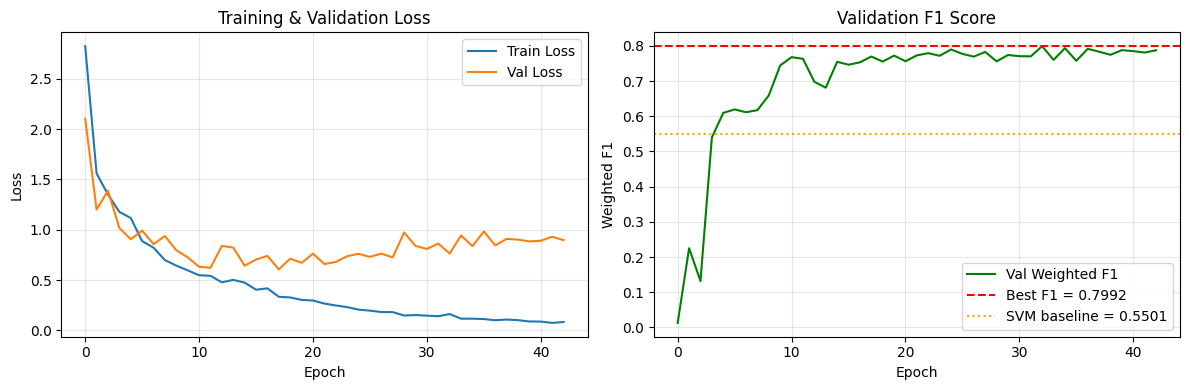

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history["train_loss"], label="Train Loss")
ax1.plot(history["val_loss"],   label="Val Loss")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
ax1.set_title("Training & Validation Loss")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(history["val_f1"], color="green", label="Val Weighted F1")
ax2.axhline(best_val_f1, color="red", linestyle="--", label=f"Best F1 = {best_val_f1:.4f}")
if SVM_BASELINE_F1:
    ax2.axhline(SVM_BASELINE_F1, color="orange", linestyle=":", label=f"SVM baseline = {SVM_BASELINE_F1:.4f}")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Weighted F1")
ax2.set_title("Validation F1 Score")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout(); plt.show()


## Cell 11 — Evaluasi pada Test Set (Session 5)

C:\Users\NicholasAH\AppData\Local\Temp\ipykernel_2332\2694424907.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(CHECKPOINT, map_locatio

Evaluasi pada test set (Session 5)...

=== CLASSIFICATION REPORT (semua prediksi) ===
              precision    recall  f1-score   support

     Neutral       0.67      0.70      0.69       383
       Happy       0.76      0.64      0.69       143
         Sad       0.82      0.75      0.78       245
       Angry       0.65      0.77      0.71       170

    accuracy                           0.72       941
   macro avg       0.73      0.71      0.72       941
weighted avg       0.72      0.72      0.72       941

Weighted F1 DIMMN    : 0.7161
Weighted F1 SVM base : 0.5501
Gain vs baseline     : +0.1660


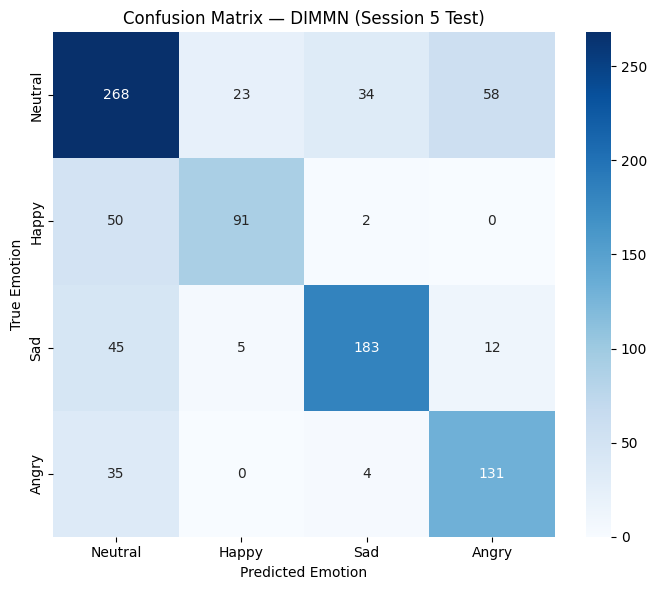

In [ ]:
import torch
import numpy as np
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Muat checkpoint terbaik
model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
model.eval()

target_names = ["Neutral", "Happy", "Sad", "Angry"]
all_preds, all_trues, all_entropies = [], [], []

print("Evaluasi pada test set (Session 5)...")

with torch.no_grad():
    for batch_audio, batch_text, batch_spk, batch_y, batch_mask in test_loader:
        batch_audio = batch_audio.to(device)
        batch_text  = batch_text.to(device)
        batch_spk   = batch_spk.to(device)
        batch_y     = batch_y.to(device)
        batch_mask  = batch_mask.to(device)

        logits  = model(batch_audio, batch_text, batch_spk)
        probs   = F.softmax(logits, dim=-1)
        entropy = -torch.sum(probs * torch.log(probs + 1e-9), dim=-1)
        preds   = torch.argmax(logits, dim=-1)

        m = batch_mask.view(-1)
        all_preds.extend(preds.view(-1)[m].cpu().numpy())
        all_trues.extend(batch_y.view(-1)[m].cpu().numpy())
        all_entropies.extend(entropy.view(-1)[m].cpu().numpy())

all_preds     = np.array(all_preds)
all_trues     = np.array(all_trues)
all_entropies = np.array(all_entropies)

print("\n=== CLASSIFICATION REPORT (semua prediksi) ===")
print(classification_report(all_trues, all_preds, target_names=target_names, zero_division=0))

DIMMN_F1 = f1_score(all_trues, all_preds, average="weighted", zero_division=0)
print(f"Weighted F1 DIMMN    : {DIMMN_F1:.4f}")
print(f"Weighted F1 SVM base : {SVM_BASELINE_F1:.4f}")
print(f"Gain vs baseline     : +{DIMMN_F1 - SVM_BASELINE_F1:.4f}")

# Confusion matrix
cm = confusion_matrix(all_trues, all_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names)
plt.title("Confusion Matrix — DIMMN (Session 5 Test)")
plt.ylabel("True Emotion"); plt.xlabel("Predicted Emotion")
plt.tight_layout(); plt.show()


## Cell 12 — Ablation Study: Entropy Gate τ
Ini adalah tabel yang **wajib ada** di thesis Anda untuk mempertahankan klaim entropy gate.

=== ABLATION: SHANNON ENTROPY GATE ===
 tau (τ) Abstain rate  N confident  Weighted F1
     0.4        29.6%          662       0.8065
     0.5        22.7%          727       0.7951
     0.6        15.0%          800       0.7640
     0.7         8.1%          865       0.7403
     0.8         3.4%          909       0.7235
     0.9         1.8%          924       0.7193
     1.0         1.2%          930       0.7191
     1.1         0.0%          941       0.7161
     1.2         0.0%          941       0.7161


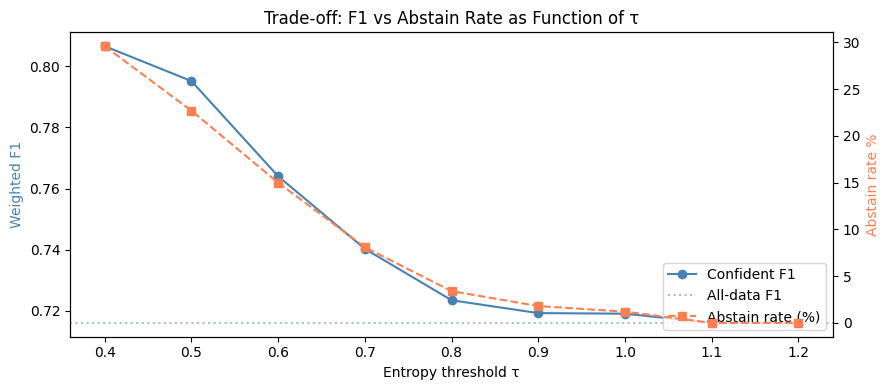


τ optimal (F1 terbaik, abstain < 25%): τ = 0.5
  Confident F1   : 0.7951
  Abstain rate   : 22.7%


In [ ]:
import pandas as pd

tau_values = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2]
ablation_results = []

for tau in tau_values:
    mask_confident = all_entropies <= tau
    n_confident    = mask_confident.sum()
    if n_confident == 0:
        continue
    f1_confident = f1_score(all_trues[mask_confident], all_preds[mask_confident],
                             average="weighted", zero_division=0)
    abstain_rate = 1.0 - mask_confident.mean()
    ablation_results.append({
        "tau (τ)":        tau,
        "Abstain rate":   f"{abstain_rate:.1%}",
        "N confident":    n_confident,
        "Weighted F1":    round(f1_confident, 4),
    })

df_ablation = pd.DataFrame(ablation_results)
print("=== ABLATION: SHANNON ENTROPY GATE ===")
print(df_ablation.to_string(index=False))

# Plot: F1 vs abstain rate sebagai fungsi tau
fig, ax1 = plt.subplots(figsize=(9, 4))
taus        = [r["tau (τ)"] for r in ablation_results]
f1s         = [r["Weighted F1"] for r in ablation_results]
abstain_pct = [float(r["Abstain rate"].replace("%","")) for r in ablation_results]

ax2 = ax1.twinx()
ax1.plot(taus, f1s,         "o-", color="steelblue",  label="Confident F1")
ax2.plot(taus, abstain_pct, "s--", color="coral",      label="Abstain rate (%)")
ax1.axhline(DIMMN_F1, color="steelblue", linestyle=":", alpha=0.5, label="All-data F1")
ax1.set_xlabel("Entropy threshold τ")
ax1.set_ylabel("Weighted F1",    color="steelblue")
ax2.set_ylabel("Abstain rate %", color="coral")
ax1.set_title("Trade-off: F1 vs Abstain Rate as Function of τ")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower right")
plt.tight_layout(); plt.show()

# Pilih τ optimal: F1 tertinggi dengan abstain rate < 25%
optimal = df_ablation[
    [float(r.replace("%","")) < 25 for r in df_ablation["Abstain rate"]]
].sort_values("Weighted F1", ascending=False).iloc[0]
print(f"\nτ optimal (F1 terbaik, abstain < 25%): τ = {optimal['tau (τ)']}")
print(f"  Confident F1   : {optimal['Weighted F1']}")
print(f"  Abstain rate   : {optimal['Abstain rate']}")


## Cell 13 — Ringkasan Hasil & Perbandingan untuk Thesis

In [ ]:
print("=" * 60)
print("     RINGKASAN HASIL — DIMMN THESIS")
print("=" * 60)
print(f"  Dataset          : IEMOCAP (4 emosi: neu/hap/sad/ang)")
print(f"  Split protocol   : Leave-One-Session-Out (Session 5 = test)")
print(f"  Test set size    : {len(all_preds)} utterances dari {len(test_seqs)} dialogs")
print()
print(f"  [BASELINE] SVM + MFCC (no sequence)")
print(f"    Weighted F1    : {SVM_BASELINE_F1:.4f}")
print()
print(f"  [DIMMN] BiLSTM + Cross-Modal Attn + Speaker Emb")
print(f"    Weighted F1    : {DIMMN_F1:.4f}")
print(f"    Improvement    : +{DIMMN_F1 - SVM_BASELINE_F1:.4f}  ({(DIMMN_F1/SVM_BASELINE_F1 - 1)*100:.1f}%)")
print()
print(f"  [ENTROPY GATE τ = {optimal['tau (τ)']}]")
print(f"    Confident F1   : {optimal['Weighted F1']}")
print(f"    Abstain rate   : {optimal['Abstain rate']}")
print()
print(f"  Target thesis    : Weighted F1 >= 0.45")
print(f"  Status           : {'TERCAPAI' if DIMMN_F1 >= 0.45 else 'BELUM — lanjutkan tuning'}")
print("=" * 60)
print()
print("Next step: Cell ini adalah output akhir dari modul klasifikasi.")
print("Langkah berikutnya: sambungkan label + confidence ke TTS (Coqui/SpeechT5).")


     RINGKASAN HASIL — DIMMN THESIS
  Dataset          : IEMOCAP (4 emosi: neu/hap/sad/ang)
  Split protocol   : Leave-One-Session-Out (Session 5 = test)
  Test set size    : 941 utterances dari 31 dialogs

  [BASELINE] SVM + MFCC (no sequence)
    Weighted F1    : 0.5501

  [DIMMN] BiLSTM + Cross-Modal Attn + Speaker Emb
    Weighted F1    : 0.7161
    Improvement    : +0.1660  (30.2%)

  [ENTROPY GATE τ = 0.5]
    Confident F1   : 0.7951
    Abstain rate   : 22.7%

  Target thesis    : Weighted F1 >= 0.45
  Status           : TERCAPAI

Next step: Cell ini adalah output akhir dari modul klasifikasi.
Langkah berikutnya: sambungkan label + confidence ke TTS (Coqui/SpeechT5).


---
# TED v1 — Conversation-Level Causal Multimodal Model + LLM Context Integration

**Continuation of the original notebook (not the Experiment 1 fork).** Run original **Cells 1–3** to load `df` and `sequences`. The former BiLSTM training section remains as a historical comparison and is **not required** to run TED. TED uses its own preparation, encoders, model, training, calibration, and inference. No scores are claimed until training actually runs.

**Document-aligned components:** WavLM Base+ DeBERTa Base (768-d hidden states), audio-query/text-key-value attention **within each utterance**, 16-d dyadic speaker embeddings, causal turn Transformer, emotion + VAD multi-task heads, temperature scaling, split conformal classification, abstention, conversation-level inference, LLM context payload.

**Implementation clarifications:** `microsoft/wavlm-base-plus` is 768-dimensional; *WavLM Large* is not. Frozen encoders are **not generative LLMs**: the downstream conversational LLM consumes TED's structured state and independently generates language. Offline feature caching here retains frame/token sequences only inside an utterance before pool/fusion, and saves utterance-level 768-d means for affordable training; this is a practical approximation to full token-frame cross-attention. Claims of true sub-200ms end-to-end inference, trained trustworthiness, domain robustness, KV caching, and human handoff are **not** established by this prototype.

**Important evaluation scope:** Sessions 1–2 training, Session 3 model selection, Session 4 temperature+conformal calibration, Session 5 untouched test. Session-held-out splits avoid speaker overlap; this is a single held-out test rather than five-fold LOSO. All annotations are treated as data, not instructions to the LLM.

## TED 1 — Dependencies and configuration

In [ ]:
# Run once in your training environment if needed:
# %pip install -U torch transformers librosa soundfile scikit-learn pandas tqdm
from pathlib import Path
import os, re, json, random, math, copy, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, classification_report, accuracy_score

TED_SEED = 42
random.seed(TED_SEED); np.random.seed(TED_SEED); torch.manual_seed(TED_SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(TED_SEED)
TED_DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TED_DIR = Path(os.environ.get('TED_WORK_DIR', str(Path.cwd() / 'ted_outputs')))
TED_DIR.mkdir(parents=True, exist_ok=True)
TED_AUDIO_MODEL = 'microsoft/wavlm-base-plus'
TED_TEXT_MODEL = 'microsoft/deberta-v3-base'
TED_SR = 16000
TED_MAX_AUDIO_SECONDS = 12
TED_MAX_TEXT_TOKENS = 128
TED_MAX_TURNS = 64   # sliding causal windows, never truncate entire long dialogue
TED_STRIDE = 64      # no overlapping loss targets during training
TED_BATCH = 4
TED_EPOCHS = 25
TED_PATIENCE = 5
TED_LR = 2e-4
TED_CLASSES = ['neutral', 'happy', 'sad', 'angry']
assert 'df' in globals() and 'sequences' in globals(), 'Run original notebook Cells 1–3 first.'
assert TED_TEXT_MODEL and TED_AUDIO_MODEL
print('TED device:', TED_DEVICE, '| output:', TED_DIR)

## TED 2 — Recover continuous VAD annotation targets

IEMOCAP's evaluation annotations contain `[valence, activation/arousal, dominance]` following each utterance label. We parse them from the *original files* and train only where all three scores are valid. Missing VAD observations are masked out of the MSE objective, **not fabricated from emotion classes**.

In [ ]:
def ted_read_vad(root):
    found = {}
    pattern = re.compile(r'^\s*\[[^]]+\]\s+(\S+)\s+\S+\s+\[\s*([-+\d.]+)\s*,\s*([-+\d.]+)\s*,\s*([-+\d.]+)\s*\]')
    for session in range(1, 6):
        emo_dir = Path(root) / f'Session{session}' / 'dialog' / 'EmoEvaluation'
        if not emo_dir.is_dir(): raise FileNotFoundError(f'Missing: {emo_dir}')
        for file in emo_dir.glob('*.txt'):
            for line in file.read_text(encoding='latin-1', errors='ignore').splitlines():
                hit = pattern.match(line)
                if hit:
                    uid, *scores = hit.groups()
                    vals = np.array([float(v) for v in scores], dtype=np.float32)
                    if np.isfinite(vals).all() and ((vals >= 1) & (vals <= 5)).all():
                        found[uid] = vals
    return found

ted_vad_lookup = ted_read_vad(IEMOCAP_ROOT)
print('Usable VAD annotations:', len(ted_vad_lookup))
assert len(ted_vad_lookup) > 0, 'No VAD ratings recovered. Check IEMOCAP annotation formatting.'
print('Selected utterances with VAD:', sum(u['utterance_id'] in ted_vad_lookup for seq in sequences for u in seq['utterances']))

## TED 3 — Frozen foundation encoders and persistent feature cache

This replaces the legacy 373-d MFCC / 384-d MiniLM features **for TED**. Audio is 16kHz mono, and both encoders output 768-d utterance vectors. The backbones are frozen and put in `eval()` mode. Pooling uses the speech output mean and attention-mask-weighted text mean. Each utterance is cached individually so long dialogues can be reconstructed without the notebook's earlier 55-turn truncation.

*First run requires network access and model weights from Hugging Face; download may be gated by organizational policy. Heavy inference is best executed with a CUDA GPU.*

In [ ]:
from transformers import AutoModel, AutoTokenizer, AutoFeatureExtractor
import librosa

TED_FEAT_CACHE = TED_DIR / 'utterance_embeddings'
TED_FEAT_CACHE.mkdir(parents=True, exist_ok=True)
_ted_audio_encoder = None
_ted_text_encoder = None
_ted_audio_proc = None
_ted_tokenizer = None

def ted_load_encoders():
    global _ted_audio_encoder, _ted_text_encoder, _ted_audio_proc, _ted_tokenizer
    if _ted_audio_encoder is None:
        _ted_audio_proc = AutoFeatureExtractor.from_pretrained(TED_AUDIO_MODEL)
        _ted_tokenizer = AutoTokenizer.from_pretrained(TED_TEXT_MODEL)
        _ted_audio_encoder = AutoModel.from_pretrained(TED_AUDIO_MODEL).to(TED_DEVICE).eval()
        _ted_text_encoder = AutoModel.from_pretrained(TED_TEXT_MODEL).to(TED_DEVICE).eval()
        for encoder in (_ted_audio_encoder, _ted_text_encoder):
            for param in encoder.parameters(): param.requires_grad_(False)
    return _ted_audio_encoder, _ted_text_encoder

def ted_embed_utterance(utt):
    uid = utt['utterance_id']
    # Name cache with model identifiers to avoid accidental stale feature reuse
    signature = re.sub(r'[^a-zA-Z0-9_-]', '_', TED_AUDIO_MODEL + '__' + TED_TEXT_MODEL)
    path = TED_FEAT_CACHE / f'{uid}__{signature}.npz'
    if path.exists():
        with np.load(path) as z:
            return z['audio'].copy(), z['text'].copy()
    a_model, t_model = ted_load_encoders()
    wav = utt['wav_path']
    if not Path(wav).is_file(): raise FileNotFoundError(wav)
    y, _ = librosa.load(wav, sr=TED_SR, mono=True, duration=TED_MAX_AUDIO_SECONDS)
    if len(y) < 400: raise ValueError(f'Invalid / too-short audio: {uid}')
    proc = _ted_audio_proc(y, sampling_rate=TED_SR, return_tensors='pt', padding=False)
    audio_in = {k:v.to(TED_DEVICE) for k,v in proc.items()}
    token = _ted_tokenizer(str(utt.get('text','') or ''), max_length=TED_MAX_TEXT_TOKENS,
                           truncation=True, return_tensors='pt')
    token = {k:v.to(TED_DEVICE) for k,v in token.items()}
    with torch.inference_mode():
        a_hidden = a_model(**audio_in).last_hidden_state
        t_hidden = t_model(**token).last_hidden_state
        a_vec = a_hidden.mean(dim=1).squeeze(0).float().cpu().numpy()
        t_mask = token['attention_mask'].unsqueeze(-1)
        t_vec = ((t_hidden * t_mask).sum(dim=1) / t_mask.sum(dim=1).clamp_min(1)).squeeze(0).float().cpu().numpy()
    if a_vec.shape != (768,) or t_vec.shape != (768,):
        raise RuntimeError(f'Feature dimensionality mismatch {a_vec.shape}, {t_vec.shape}')
    np.savez_compressed(path, audio=a_vec.astype('float32'), text=t_vec.astype('float32'))
    return a_vec.astype('float32'), t_vec.astype('float32')

# Run to build all embeddings once; restart-safe.
ted_by_utterance = {}
for s in tqdm(sequences, desc='TED foundation-feature cache'):
    for u in s['utterances']:
        ted_by_utterance[u['utterance_id']] = ted_embed_utterance(u)
print('Cached utterances:', len(ted_by_utterance))

## TED 4 — Full conversation windows, local speaker IDs, and leakage-safe splits

Each dialogue retains chronological order. Speaker embeddings encode `F` or `M` **within a conversation**, not global actor identity. A 64-turn window is processed causally. For longer conversations, independent windows do not carry state across window boundaries during training; streaming inference keeps a sliding window of prior turns. No turn has access to future utterances.

In [ ]:
def ted_windows(sessions, size=TED_MAX_TURNS, stride=TED_STRIDE):
    rows=[]
    for seq in sequences:
        if int(seq['session']) not in sessions: continue
        utterances = seq['utterances']
        for start in range(0, len(utterances), stride):
            seg=utterances[start:start+size]
            if seg:
                rows.append((seq['dialog_id'], seg))
    return rows

class TEDConversationDataset(Dataset):
    def __init__(self, sessions): self.rows = ted_windows(set(sessions))
    def __len__(self): return len(self.rows)
    def __getitem__(self, index):
        did, utts=self.rows[index]
        aud=np.stack([ted_by_utterance[u['utterance_id']][0] for u in utts])
        txt=np.stack([ted_by_utterance[u['utterance_id']][1] for u in utts])
        spk=np.array([SPEAKER_TO_IDX[u['speaker']] for u in utts],dtype='int64')
        lab=np.array([u['label'] for u in utts],dtype='int64')
        vad=np.stack([ted_vad_lookup.get(u['utterance_id'], np.full(3,np.nan,dtype='float32')) for u in utts])
        return {'audio':torch.from_numpy(aud),'text':torch.from_numpy(txt),'speaker':torch.from_numpy(spk),
                'labels':torch.from_numpy(lab),'vad':torch.from_numpy(vad),
                'ids':[u['utterance_id'] for u in utts], 'dialog_id':did}

def ted_collate(batch):
    B=len(batch); T=max(x['labels'].shape[0] for x in batch)
    out={'audio':torch.zeros(B,T,768),'text':torch.zeros(B,T,768),
         'speaker':torch.zeros(B,T,dtype=torch.long),'labels':torch.full((B,T),-100,dtype=torch.long),
         'vad':torch.full((B,T,3),float('nan')),'mask':torch.zeros(B,T,dtype=torch.bool),
         'ids':[x['ids'] for x in batch],'dialog_id':[x['dialog_id'] for x in batch]}
    for i,x in enumerate(batch):
        t=len(x['labels'])
        for k in ['audio','text','speaker','labels','vad']: out[k][i,:t]=x[k]
        out['mask'][i,:t]=True
    return out

TED_SESSIONS = {'train': [1,2], 'val':[3], 'cal':[4], 'test':[5]}
assert len(set(sum(TED_SESSIONS.values(), [])))==5
TED_LOADERS={k:DataLoader(TEDConversationDataset(v),batch_size=TED_BATCH,
                          shuffle=(k=='train'),collate_fn=ted_collate,num_workers=0)
             for k,v in TED_SESSIONS.items()}
print({k:len(dl.dataset) for k,dl in TED_LOADERS.items()})

## TED 5 — Causal Transformer + gated cross-modal fusion + dual-head MTL

Audio-query/text-key-value attention is applied **within each aligned utterance** (one projected vector each), not across future conversation turns. With pooled utterance vectors this degenerates to a learned projection (attention has one key); the dynamic gate supplies the effective multimodal weighting. For richer frame-to-token fusion, extend `ted_embed_utterance()` to cache variable-length hidden states and implement per-utterance token-frame cross-attention. The causal turn Transformer below implements real multi-turn context modeling.

In [ ]:
class TEDNet(nn.Module):
    def __init__(self,dim=256,heads=4,layers=3,dropout=.15,max_turns=TED_MAX_TURNS):
        super().__init__()
        self.audio_proj=nn.Sequential(nn.Linear(768,dim),nn.LayerNorm(dim),nn.GELU())
        self.text_proj=nn.Sequential(nn.Linear(768,dim),nn.LayerNorm(dim),nn.GELU())
        self.cross_modal=nn.MultiheadAttention(dim,heads,dropout=dropout,batch_first=True)
        self.gate=nn.Sequential(nn.Linear(dim*2,dim),nn.Sigmoid())
        self.speaker=nn.Embedding(2,16)
        self.fuse=nn.Sequential(nn.Linear(dim+16,dim),nn.LayerNorm(dim),nn.Dropout(dropout))
        self.position=nn.Embedding(max_turns,dim)
        layer=nn.TransformerEncoderLayer(d_model=dim,nhead=heads,dim_feedforward=4*dim,
                                          dropout=dropout,batch_first=True,activation='gelu',norm_first=True)
        self.temporal=nn.TransformerEncoder(layer,num_layers=layers,enable_nested_tensor=False)
        self.classifier=nn.Linear(dim,4)
        self.vad_head=nn.Linear(dim,3)
        # Learnable homoscedastic task weighting (stable log variance form)
        self.task_logvars=nn.Parameter(torch.zeros(2))
    def forward(self,audio,text,speaker,mask):
        B,T,_=audio.shape
        assert T<=self.position.num_embeddings, 'Turn window larger than configured positional embeddings'
        a=self.audio_proj(audio); t=self.text_proj(text)
        # per-utterance cross attention: no cross-turn information at this stage
        cross,_=self.cross_modal(a.reshape(B*T,1,-1),t.reshape(B*T,1,-1),t.reshape(B*T,1,-1),need_weights=False)
        cross=cross.reshape(B,T,-1)
        g=self.gate(torch.cat([a,t],dim=-1))
        mixed=g*a+(1-g)*(t+cross)*0.5
        fused=self.fuse(torch.cat([mixed,self.speaker(speaker)],dim=-1))
        fused=fused+self.position(torch.arange(T,device=audio.device))[None,:,:]
        causal=torch.triu(torch.ones(T,T,dtype=torch.bool,device=audio.device),diagonal=1)
        context=self.temporal(fused,mask=causal,src_key_padding_mask=~mask)
        logits=self.classifier(context)
        vad=1.0+4.0*torch.sigmoid(self.vad_head(context))
        return {'logits':logits,'vad':vad,'gate':g}

def ted_loss(model,pred,batch):
    ce=F.cross_entropy(pred['logits'].reshape(-1,4),batch['labels'].reshape(-1),ignore_index=-100)
    has_vad=batch['mask'].unsqueeze(-1) & torch.isfinite(batch['vad'])
    if has_vad.any():
        squared=(pred['vad']-torch.nan_to_num(batch['vad'],nan=0)).square()
        mse=squared[has_vad].mean()
        lv=model.task_logvars.clamp(-5,5)
        loss=.5*torch.exp(-lv[0])*ce+.5*lv[0]+.5*torch.exp(-lv[1])*mse+.5*lv[1]
    else:
        mse=ce.new_zeros(())
        loss=ce  # do not optimize the VAD task uncertainty without supervision
    return loss,ce.detach(),mse.detach()

ted_model=TEDNet().to(TED_DEVICE)
with torch.no_grad():
    trial=ted_model(torch.randn(2,5,768,device=TED_DEVICE),torch.randn(2,5,768,device=TED_DEVICE),
                    torch.zeros(2,5,dtype=torch.long,device=TED_DEVICE),
                    torch.ones(2,5,dtype=torch.bool,device=TED_DEVICE))
assert trial['logits'].shape==(2,5,4) and trial['vad'].shape==(2,5,3)
print('Trainable parameters:',sum(p.numel() for p in ted_model.parameters() if p.requires_grad))

## TED 6 — Training, validation, checkpoint, and predictions

In [ ]:
def ted_move(batch):
    return {k:(v.to(TED_DEVICE) if isinstance(v,torch.Tensor) else v) for k,v in batch.items()}

@torch.no_grad()
def ted_predict_loader(model,loader):
    model.eval(); rows=[]
    for raw in loader:
        batch=ted_move(raw)
        pred=model(batch['audio'],batch['text'],batch['speaker'],batch['mask'])
        for i in range(batch['mask'].shape[0]):
            for j,uid in enumerate(batch['ids'][i]):
                rows.append({'utterance_id':uid,'dialog_id':batch['dialog_id'][i],
                             'label':int(batch['labels'][i,j]),
                             'logits':pred['logits'][i,j].cpu().numpy(),
                             'vad_pred':pred['vad'][i,j].cpu().numpy(),
                             'vad_true':batch['vad'][i,j].cpu().numpy()})
    return rows

def ted_weighted_f1(rows):
    return f1_score([r['label'] for r in rows], [int(np.argmax(r['logits'])) for r in rows],average='weighted',zero_division=0)

def ted_train(model=ted_model):
    opt=torch.optim.AdamW(model.parameters(),lr=TED_LR,weight_decay=.01)
    best=-1; patience=0; history=[]
    for epoch in range(1,TED_EPOCHS+1):
        model.train(); running=[]
        for raw in TED_LOADERS['train']:
            batch=ted_move(raw)
            opt.zero_grad(set_to_none=True)
            pred=model(batch['audio'],batch['text'],batch['speaker'],batch['mask'])
            loss,_,_=ted_loss(model,pred,batch)
            if not torch.isfinite(loss): raise ValueError('Non-finite loss')
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
            running.append(float(loss.item()))
        val_rows=ted_predict_loader(model,TED_LOADERS['val'])
        score=ted_weighted_f1(val_rows)
        history.append({'epoch':epoch,'train_loss':float(np.mean(running)),'val_weighted_f1':score})
        print(f'Epoch {epoch:02d} | loss {np.mean(running):.4f} | val weighted F1 {score:.4f}')
        if score>best+1e-5:
            best=score; patience=0
            torch.save({'state_dict':model.state_dict(),'config':{'audio':TED_AUDIO_MODEL,'text':TED_TEXT_MODEL,
                       'classes':TED_CLASSES,'max_turns':TED_MAX_TURNS}},TED_DIR/'ted_best.pt')
        else:
            patience+=1
            if patience>=TED_PATIENCE: break
    pd.DataFrame(history).to_csv(TED_DIR/'ted_training_history.csv',index=False)
    checkpoint=torch.load(TED_DIR/'ted_best.pt',map_location=TED_DEVICE,weights_only=True)
    model.load_state_dict(checkpoint['state_dict']);model.eval()
    return history

ted_history=ted_train()
print('Best checkpoint:',TED_DIR/'ted_best.pt')

## TED 7 — Temperature calibration + split conformal sets + risk/coverage

Calibration uses **Session 4 only**, never the test set. A conformal prediction set has finite-sample **marginal** coverage under exchangeability; because sequential utterances within conversations are correlated, that guarantee does **not automatically hold** for this dataset or deployment drift. An empty set is not proof of OOD. Abstention is `len(set) != 1`. This section separates model selection, calibration and final test.

In [ ]:
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp

ted_cal_rows=ted_predict_loader(ted_model,TED_LOADERS['cal'])
cal_logits=np.stack([r['logits'] for r in ted_cal_rows]).astype('float64')
cal_y=np.array([r['label'] for r in ted_cal_rows],dtype=int)

def ted_nll(log_temp):
    z=cal_logits/np.exp(log_temp)
    return float(np.mean(logsumexp(z,axis=1)-z[np.arange(len(cal_y)),cal_y]))

ted_opt=minimize_scalar(ted_nll,bounds=(-3,3),method='bounded')
TED_TEMPERATURE=float(np.exp(ted_opt.x))

def ted_prob(logits,temperature=TED_TEMPERATURE):
    z=np.asarray(logits,dtype=np.float64)/temperature
    z=z-z.max(axis=-1,keepdims=True)
    p=np.exp(z)
    return p/p.sum(axis=-1,keepdims=True)

TED_ALPHA=0.10
cal_probs=ted_prob(cal_logits)
cal_scores=1-cal_probs[np.arange(len(cal_y)),cal_y]
n=len(cal_scores)
rank=int(np.ceil((n+1)*(1-TED_ALPHA)))
TED_Q=float('inf') if rank>n else float(np.sort(cal_scores)[rank-1])

def ted_decide(logits,vad,threshold=TED_Q):
    prob=ted_prob(logits)
    label_set=[TED_CLASSES[i] for i,p in enumerate(prob) if 1-p<=threshold]
    accepted=len(label_set)==1
    return {'emotion':label_set[0] if accepted else None,
            'probabilities':{name:float(p) for name,p in zip(TED_CLASSES,prob)},
            'prediction_set':label_set,'abstain_flag':not accepted,
            'entropy':float(-(prob*np.log(np.maximum(prob,1e-12))).sum()),
            'vad':{'valence':float(vad[0]),'arousal':float(vad[1]),'dominance':float(vad[2])}}

ted_test_rows=ted_predict_loader(ted_model,TED_LOADERS['test'])
ted_test_y=[r['label'] for r in ted_test_rows]
ted_test_pred=[int(np.argmax(r['logits'])) for r in ted_test_rows]
ted_test_decisions=[ted_decide(r['logits'],r['vad_pred']) for r in ted_test_rows]
ted_accept=np.array([not x['abstain_flag'] for x in ted_test_decisions])
print('TEST Weighted F1:',f1_score(ted_test_y,ted_test_pred,average='weighted',zero_division=0))
print('TEST Macro F1:',f1_score(ted_test_y,ted_test_pred,average='macro',zero_division=0))
print('TEST Coverage:',float(ted_accept.mean()))
if ted_accept.any():
    print('TEST selective accuracy:',accuracy_score(np.array(ted_test_y)[ted_accept],np.array(ted_test_pred)[ted_accept]))
print('TEST empirical set coverage:',np.mean([TED_CLASSES[y] in d['prediction_set'] for y,d in zip(ted_test_y,ted_test_decisions)]))
print(classification_report(ted_test_y,ted_test_pred,target_names=TED_CLASSES,zero_division=0))
with open(TED_DIR/'ted_calibration.json','w') as f:
    json.dump({'temperature':TED_TEMPERATURE,'alpha':TED_ALPHA,'quantile':TED_Q,
               'calibration_size':len(ted_cal_rows),'classes':TED_CLASSES},f,indent=2)
with open(TED_DIR/'ted_test_decisions.jsonl','w') as f:
    for r,d in zip(ted_test_rows,ted_test_decisions):
        f.write(json.dumps({'utterance_id':r['utterance_id'],'true_label':TED_CLASSES[r['label']],**d})+'\n')

## TED 8 — Stateful conversation inference (no future turns) and LLM-ready context

For streaming, the runtime maintains only **past/current turns**, and re-evaluates a capped history window. This is correct causal inference but **not** a true key/value cache. `LLM` denotes the downstream generative model; no API credentials or external calls are made. The API accepts structured prior-turn data and generates a safe instruction payload. The model is a *multimodal ERC backbone*, not a pretrained generative LLM.

In [ ]:
from collections import deque

class TEDConversationSession:
    def __init__(self,model=ted_model,max_turns=TED_MAX_TURNS):
        self.model=model.eval()
        self.turns=deque(maxlen=max_turns)
    @torch.inference_mode()
    def add_precomputed_turn(self,audio768,text768,speaker,text=''):
        if speaker not in SPEAKER_TO_IDX: raise ValueError('speaker must be F or M within this dialogue')
        a=np.asarray(audio768,dtype='float32');t=np.asarray(text768,dtype='float32')
        if a.shape!=(768,) or t.shape!=(768,): raise ValueError('Expected 768-d frozen backbone embeddings')
        self.turns.append({'audio':a,'text':t,'speaker':SPEAKER_TO_IDX[speaker], 'speaker_name':speaker,'transcript':str(text)})
        audio=torch.from_numpy(np.stack([v['audio'] for v in self.turns]))[None].to(TED_DEVICE)
        text_vectors=torch.from_numpy(np.stack([v['text'] for v in self.turns]))[None].to(TED_DEVICE)
        speakers=torch.tensor([[v['speaker'] for v in self.turns]],device=TED_DEVICE)
        mask=torch.ones(1,len(self.turns),dtype=torch.bool,device=TED_DEVICE)
        out=self.model(audio,text_vectors,speakers,mask)
        decision=ted_decide(out['logits'][0,-1].cpu().numpy(),out['vad'][0,-1].cpu().numpy())
        return {'turn_count':len(self.turns),'speaker':speaker,'transcript':str(self.turns[-1]['transcript']),**decision}
    def add_iemocap_turn(self,utterance):
        a,t=ted_embed_utterance(utterance)
        return self.add_precomputed_turn(a,t,utterance['speaker'],utterance.get('text',''))

def ted_llm_context(decision,history=None):
    """Safe context for an independently configured LLM; not a generated response."""
    accepted=not decision['abstain_flag']
    return {
       'system_instruction':(
           'Respond helpfully to the latest user message. Emotion estimates are uncertain, '
           'are not clinical diagnoses, and must never override user intent. '
           "Do not claim to know the user's feelings. "
           + ('Use subtle tone adaptation only; do not reveal emotion scores unless asked.' if accepted
              else 'Emotion classification was withheld: use a neutral, non-assumptive tone; ask for clarification where appropriate.')
       ),
       'emotion_decision':{'accepted':accepted,'emotion':decision['emotion'] if accepted else None,
                           'vad':decision['vad'] if accepted else None,
                           'uncertainty_entropy':decision['entropy'],'prediction_set':decision['prediction_set']},
       'recent_transcript':list(history or [])[-8:]
    }

# Example ONLY after training/calibration: consume the first held-out conversation causally.
example_seq=next(s for s in sequences if s['session']==5)
session=TEDConversationSession()
for utterance in example_seq['utterances'][:min(5,len(example_seq['utterances']))]:
    latest=session.add_iemocap_turn(utterance)
context=ted_llm_context(latest,history=[{'speaker':u['speaker'],'text':u['text']} for u in example_seq['utterances'][:5]])
print(json.dumps(context,indent=2))

## TED 9 — Explicit next engineering steps and limitations

1. **LLM integration:** connect `ted_llm_context()` to your chosen local/API chat model. The LLM receives the latest text and conversation history; TED classifies emotion. The LLM is not silently used as a replacement classifier.
2. **Higher-fidelity cross-modal attention:** cache WavLM frame vectors and DeBERTa token vectors and attend *within the same utterance* prior to turn aggregation. Current pooled-vector attention has a single key, so is mathematically weak.
3. **True KV caching:** current sliding-window inference recomputes the entire window. Implement and test per-layer K/V cache before claiming the deployment latency budget in the document.
4. **Audio streaming:** take complete utterances or implement endpoint/VAD segmentation; incremental waveform chunks are not currently supported.
5. **Calibration coverage:** with only five sessions, independence assumptions are weak. Validate conformal coverage at the conversation/session level and on shifted domains before suggesting guarantees.
6. **OOD/handoff:** neither empty conformal sets nor entropy constitutes a validated OOD detector; human handoff needs a separate application policy.
7. **No fake results:** local IEMOCAP and pretrained weights must be available to execute training. Source document's 200 ms total SLA is a target, **not a verified throughput result**.
8. **Publication-grade evaluation:** repeat held-out-session runs with the full four-way train/val/cal/test split rotated carefully, or use a separately reserved calibration corpus.
